# 01 · Data overview and sensor faults

**Goal:** merge the 11 IoT pond exports, check data quality and count readings that fall outside the valid ranges for aquaculture.

**Input:** `data/raw/IoTPond*.csv` · **Output:** `results/descriptive_statistics_by_pond.xlsx`, `results/wrong_values_per_pond.csv`, `results/wrong_values_overall.csv`

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import importlib
import src.pond_pipeline
importlib.reload(src.pond_pipeline)  # pick up edits to src/ even if this kernel imported it earlier
from src.pond_pipeline import *  # noqa: F401,F403  (column names, thresholds, helpers)

# Raw pond CSVs live in data/raw/ (see data/README.md). Override with POND_RAW_DIR if needed.
RAW = Path(os.environ.get("POND_RAW_DIR", RAW_DIR))
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.float_format", "{:.3f}".format)
df = load_all_ponds(RAW)
print(df.shape)
df.groupby("pond_id").agg(rows=("timestamp", "size"), start=("timestamp", "min"), end=("timestamp", "max"))

(1114882, 11)


,rows,start,end
pond_id,,,
1,83124,2021-06-19 00:00:05,2021-10-13 04:14:22
2,172249,2021-06-19 00:00:05,2021-10-31 04:33:00
3,169185,2021-06-19 00:00:04,2021-10-12 15:05:46
4,89797,2021-06-19 00:00:22,2021-09-05 23:58:59
6,91015,2021-06-19 00:01:46,2021-10-13 03:15:56
7,279612,2021-06-18 13:02:10,2021-12-30 20:37:56
8,70744,2021-06-18 13:06:49,2021-12-06 11:35:02
9,151785,2021-06-18 12:11:39,2021-10-13 04:37:10
10,620,2021-06-25 15:48:59,2021-12-05 00:00:00


## Date check per pond

Some exports write dates day-first (`7/11/2021` = 7 November), others month-first. For each pond the loader tries both orders, and both the `created_at` and `Date` columns, and keeps the reading in which the rows stay in time order. `chronological` should be close to 1 and `days` should match the experiment length; a pond spanning far more days than the others points to a date problem. `parsed` is the share of rows with sensor data that got a date from either column; rows without one are dropped, and `unparsed rows with data` counts them. `stale weights replaced` is explained in the next section.

In [3]:
timestamp_report(RAW)

,column,dayfirst,parsed,chronological,unparsed rows with data,start,end,days,rows,stale weights replaced,rows after restock dropped
pond_id,,,,,,,,,,,
1,created_at,True,1.000,1.000,0,2021-06-19 00:00:05,2021-10-13 04:14:22,116,83124,0,0
2,created_at,True,1.000,1.000,0,2021-06-19 00:00:05,2021-10-31 04:33:00,134,172249,3640,0
3,created_at,True,1.000,1.000,0,2021-06-19 00:00:04,2021-10-12 15:05:46,115,169185,0,0
4,created_at,True,1.000,1.000,0,2021-06-19 00:00:22,2021-09-05 23:58:59,78,89797,67,0
6,created_at,True,1.000,1.000,0,2021-06-19 00:01:46,2021-10-13 03:15:56,116,91015,493,0
7,created_at,True,1.000,1.000,0,2021-06-18 13:02:10,2021-12-30 20:37:56,195,279612,0,0
8,created_at,True,1.000,1.000,0,2021-06-18 13:06:49,2021-12-06 11:35:02,170,70744,1278,0
9,created_at,True,1.000,1.000,0,2021-06-18 12:11:39,2021-10-13 04:37:10,116,151785,0,0
10,created_at,True,1.000,1.000,0,2021-06-25 15:48:59,2021-12-05 00:00:00,162,620,1,0


If a pond has unparsed rows, the most common date strings that could not be read are listed here. Set `POND_DATES` to the pond to inspect.

In [4]:
POND_DATES = int(os.environ.get("POND_DATES", 7))
unparsed_timestamps(Path(RAW) / f"IoTPond{POND_DATES}.csv")

,created_at,Date,rows


## Fish weight per day

Fish are weighed on sampling days, so each day should carry one weight that rises over time. In some exports the sensor rows between sampling days keep an old weight: pond 11 logs a new weight about every two weeks (589 g, 626 g, 644 g, 701 g) while all other rows stay at 281 g, so the weight jumps up on each sampling day and falls back the next. The loader therefore gives each day the highest weight logged that day and keeps the latest sampling weight until a higher one is logged (`fix_stale_weights` in `src/pond_pipeline.py`). Pond 11 was restocked with a new batch of fish on 4 Feb 2022 (303 g); the few days after that are left out (`RESTOCK_DATES`), so they do not appear below. The table compares the weights as logged with the weight used. Change `POND_CHECK` to inspect another pond.

In [5]:
POND_CHECK = int(os.environ.get("POND_CHECK", 11))
logged = load_pond(Path(RAW) / f"IoTPond{POND_CHECK}.csv", fix_weights=False)
daily = weight_by_day(logged, POND_CHECK)
daily["weight used"] = df[df["pond_id"] == POND_CHECK].groupby(df["timestamp"].dt.date)[WEIGHT].max()
daily["change vs previous day (logged)"] = daily["max weight"].diff()
print(f"Pond {POND_CHECK}: {len(daily)} days, {(daily['distinct weights'] > 1).sum()} days with more than one logged weight, "
      f"{(daily['change vs previous day (logged)'] < -20).sum()} drops of more than 20 g as logged, "
      f"{(daily['weight used'].diff() < 0).sum()} drops in the weight used")
daily[(daily["distinct weights"] > 1) | (daily["change vs previous day (logged)"].abs() > 20)]

Pond 11: 120 days, 4 days with more than one logged weight, 4 drops of more than 20 g as logged, 0 drops in the weight used


,rows,distinct weights,min weight,max weight,weight used,change vs previous day (logged)
timestamp,,,,,,
2021-10-10,1,1,281.200,281.200,281.200,240.271
2021-10-24,2,2,281.200,588.771,588.771,307.571
2021-10-25,1,1,281.200,281.200,588.771,-307.571
2021-11-07,1414,2,281.200,625.886,625.886,344.686
2021-11-08,1,1,281.200,281.200,625.886,-344.686
2021-11-21,384,2,281.200,644.357,644.357,363.157
2021-11-22,1,1,281.200,281.200,644.357,-363.157
2021-12-05,621,2,281.200,701.000,701.000,419.800
2021-12-06,1,1,281.200,281.200,701.000,-419.800


## Missing values and raw ranges

Raw readings include clear sensor faults (for example a temperature of -127 °C, the DS18B20 error code), so the raw min/max are shown before any cleaning.

In [6]:
df.isna().sum()

pond_id                        0
timestamp                      0
Temperature (C)                0
Turbidity(NTU)                 0
Dissolved Oxygen(mg/L)         0
PH                             0
Ammonia(mg/L)             198294
Nitrate(mg/L)                  0
Population                     0
Fish_Length(cm)             2634
Fish_Weight(g)                 0
dtype: int64

In [7]:
df[SENSOR_COLS + [LENGTH, WEIGHT]].describe().T

,count,mean,std,min,25%,50%,75%,max
Temperature (C),1114882.000,24.744,1.722,-127.000,24.000,24.688,25.375,31.688
Turbidity(NTU),1114882.000,61.746,41.971,-97.000,32.000,83.000,100.000,100.000
Dissolved Oxygen(mg/L),1114882.000,11.392,11.152,0.000,3.617,6.711,15.461,44.980
PH,1114882.000,5.780,3.035,-3.137,5.052,7.203,7.489,16.231
Ammonia(mg/L),916588.000,185753647.013,8257409830.572,0.000,0.355,1.958,47.584,997000000000.000
Nitrate(mg/L),1114882.000,7.732,6.122,0.000,2.770,5.620,11.290,40.950
Fish_Length(cm),1112248.000,22.598,13.266,6.740,14.040,17.700,31.267,69.986
Fish_Weight(g),1114882.000,154.819,210.526,2.869,25.910,51.720,264.310,1026.457


## Descriptive statistics per pond

In [8]:
stats = df.groupby("pond_id")[SENSOR_COLS + [POPULATION, LENGTH, WEIGHT]].agg(["mean", "median", "std", "min", "max"])
comparative = stats.T  # rows: parameter x statistic, columns: pond
comparative.to_excel(RESULTS_DIR / "descriptive_statistics_by_pond.xlsx")
comparative.head(10)

pond_id                      1        2        3        4       6        7   \
Temperature (C) mean     24.573   24.983   23.779   24.778  24.507   25.545   
                median   24.562   24.938   23.750   24.750  24.312   25.375   
                std       0.862    0.902    1.549    0.806   0.941    1.438   
                min    -127.000 -127.000 -127.000 -127.000  22.562 -127.000   
                max      27.750   27.812   26.562   26.625  28.062   30.250   
Turbidity(NTU)  mean     87.490   90.975   83.385   96.476  98.293   31.197   
                median  100.000  100.000   98.000  100.000 100.000   33.000   
                std      25.860   21.100   26.652    6.305   6.093    8.918   
                min       1.000    1.000    8.000   80.000   8.000  -10.000   
                max     100.000  100.000  100.000  100.000 100.000  100.000   

pond_id                      8        9        10       11       12  
Temperature (C) mean     24.923   24.197   22.164   24.415   25.863  
                median   24.875   24.125   27.125   26.125   25.875  
                std       1.471    0.960   27.272   15.817    2.612  
                min    -127.000 -127.000 -127.000 -127.000 -127.000  
                max      30.500   27.700   31.688   27.375   27.125  
Turbidity(NTU)  mean     -0.782   33.068   40.361   89.347   51.737  
                median   22.000   10.000   -9.000  100.000   51.000  
                std      41.589   49.967   58.229   25.095    5.965  
                min     -56.000  -57.000  -97.000  -95.000   51.000  
                max     100.000  100.000  100.000  100.000  100.000

## Readings outside the reference range

The reference ranges for catfish aquaculture are defined once in `src/pond_pipeline.py` (`VALID_RANGES`). The cleaning in notebook 03 uses the same ranges (`CLEANING_RANGES`) with one exception: dissolved oxygen below 5 mg/L is a stress level for the fish, not a sensor fault, so it is counted here but only impossible values are removed: 0 mg/L or less (sensor dropout) and above 20 mg/L.

In [9]:
pd.DataFrame({"reference range (reported)": {c: f"{lo} – {hi}" for c, (lo, hi) in VALID_RANGES.items()},
              "removed as fault outside": {c: f"{lo} – {hi}" for c, (lo, hi) in CLEANING_RANGES.items()}})

,reference range (reported),removed as fault outside
Temperature (C),20.0 – 30.0,20.0 – 30.0
PH,6.5 – 8.5,6.5 – 8.5
Dissolved Oxygen(mg/L),5.0 – None,0.01 – 20.0
Turbidity(NTU),0.0 – 50.0,0.0 – 50.0
Nitrate(mg/L),0.0 – 25.0,0.0 – 25.0
Ammonia(mg/L),0.0 – 0.1,0.0 – 0.1


In [10]:
overall = wrong_value_summary(df, by=None)
overall.to_csv(RESULTS_DIR / "wrong_values_overall.csv")
overall

,Wrong values,Percentage (%)
Temperature (C),128,0.011
PH,332572,29.830
Dissolved Oxygen(mg/L),379086,34.002
Turbidity(NTU),750901,67.353
Nitrate(mg/L),194,0.017
Ammonia(mg/L),741287,66.490


In [11]:
per_pond = wrong_value_summary(df, by="pond_id")
per_pond.to_csv(RESULTS_DIR / "wrong_values_per_pond.csv")
per_pond

,Total rows,Temperature (C),PH,Dissolved Oxygen(mg/L),Turbidity(NTU),Nitrate(mg/L),Ammonia(mg/L),Temperature (C) (%),PH (%),Dissolved Oxygen(mg/L) (%),Turbidity(NTU) (%),Nitrate(mg/L) (%),Ammonia(mg/L) (%)
pond_id,,,,,,,,,,,,,
1,83124,1,428,30817,75291,0,82902,0.001,0.515,37.074,90.577,0.000,99.733
2,172249,1,79816,98744,162582,0,171811,0.001,46.338,57.326,94.388,0.000,99.746
3,169185,15,7532,40183,142672,4,142939,0.009,4.452,23.751,84.329,0.002,84.487
4,89797,1,1109,39852,89797,4,57788,0.001,1.235,44.380,100.000,0.004,64.354
6,91015,0,29255,26962,90637,75,55454,0.000,32.143,29.624,99.585,0.082,60.928
7,279612,35,110514,69407,7971,97,89280,0.013,39.524,24.823,2.851,0.035,31.930
8,70744,10,31324,29064,30596,4,17473,0.014,44.278,41.083,43.249,0.006,24.699
9,151785,1,68501,41635,144003,0,119839,0.001,45.130,27.430,94.873,0.000,78.953
10,620,28,598,502,612,0,102,4.516,96.452,80.968,98.710,0.000,16.452


Turbidity and ammonia are out of range in most readings, so they are dropped before modelling. For dissolved oxygen the percentage is the share of readings below the 5 mg/L stress level. Temperature, dissolved oxygen, pH and nitrate are kept.

## Correlations after removing sensor faults

Computed after the cleaning ranges are applied; on raw data the matrix mostly reflects sensor error codes.

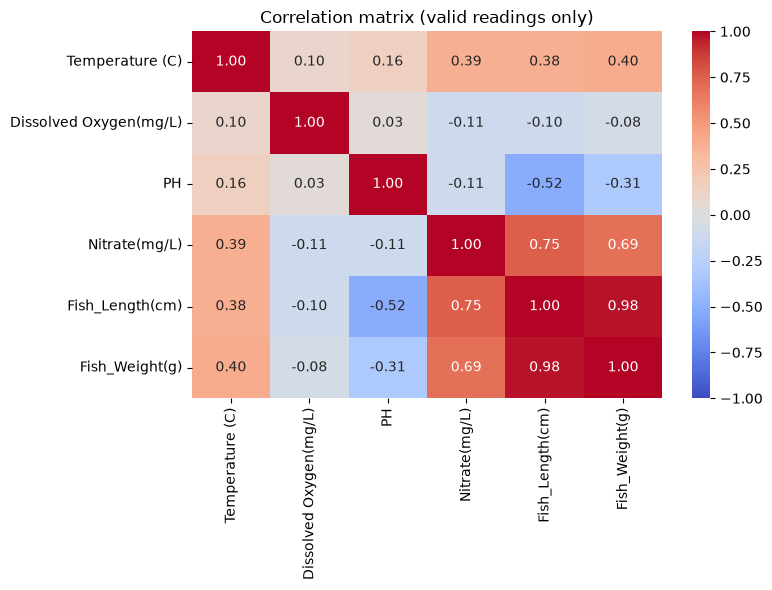

In [12]:
valid = remove_invalid(df)
corr = valid[MODEL_SENSOR_COLS + [LENGTH, WEIGHT]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix (valid readings only)")
plt.tight_layout()
plt.show()

Fish length and weight are almost perfectly correlated: they are measured together on sampling days. This is why length is **not** used as a feature to predict weight in notebooks 04 and 05.